# Synthetic cohort: parameter recovery and noise robustness

ESILV A4 DIA3 — Louis Le Forestier and Team

This completed experiment preserves the supplied population generator and outcome equation. It measures whether models recover the known coefficients and how controlled survey errors affect ranking and probability accuracy.

Run top to bottom. The default verifies source fingerprints and displays the saved experiment. `RERUN_EXPERIMENTS=1` recomputes all three cohorts and all 12 scenarios. The historical filename is retained for existing links; this is the completed analysis.

## 1. Environment and reproducibility

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run from the repository or notebooks directory."
sys.path.insert(0, str(ROOT))
from src.experiment import run

OUT = ROOT / "results"
if os.environ.get("RERUN_EXPERIMENTS") == "1" or not (OUT / "run_manifest.json").exists():
    run()
manifest = json.loads((OUT / "run_manifest.json").read_text())
for name, expected in manifest["source_sha256"].items():
    actual = hashlib.sha256((ROOT / "src" / name).read_bytes()).hexdigest()
    assert actual == expected, f"Source changed: {name}. Rerun with RERUN_EXPERIMENTS=1."
print("Completed run:", manifest["completed_at_utc"])
print("Python:", manifest["python"], "Libraries:", manifest["versions"])
print("Experiment duration (seconds):", round(manifest["elapsed_seconds"], 2))
pd.set_option("display.max_colwidth", 110)


Completed run: 2026-11-16T12:21:33.635455+00:00
Python: 3.14.10 Libraries: {'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.1'}
Experiment duration (seconds): 30.12


## 2. Known generating equation

The outcome probability is `sigmoid(η)`, with:

`η = -4.80 + .08(BMI−25) + .75 HighBP + .55 HighChol + .45(GenHlth−1) + .15(Age−1) − .30 PhysActivity + .20 Smoker − .15 HvyAlcoholConsump − .10 Fruits − .10 Veggies`.

A Bernoulli draw generates the observed outcome. Sex has coefficient zero. The coefficients are experimental assumptions, not epidemiological estimates. In uncentered coordinates, the true intercept is **−7.40**, not −4.80. Standardized fitted coefficients must be divided by training standard deviations, and the intercept must account for training means before comparison.

The original generator is unchanged: age has 13 bands, BMI is a clipped normal variable, lifestyle variables are Bernoulli, and blood pressure/cholesterol/general health depend on age and BMI. It represents selected correlations but is not a calibrated epidemiological simulator.

In [2]:
from src.generator import TRUE_BETAS, RAW_INTERCEPT
print("Raw-coordinate intercept:", RAW_INTERCEPT)
display(pd.Series(TRUE_BETAS, name="defined coefficient").to_frame())
display(pd.read_csv(OUT / "cohort_audit.csv"))

Raw-coordinate intercept: -7.4


,defined coefficient
intercept,-4.80
BMI,0.08
HighBP,0.75
HighChol,0.55
GenHlth,0.45
Age,0.15
PhysActivity,-0.30
Smoker,0.20
HvyAlcoholConsump,-0.15
Fruits,-0.10


,seed,rows,observed_prevalence,mean_true_probability,train_rows,test_rows,train_index_sha256,test_index_sha256
0,42,50000,0.19052,0.190574,40000,10000,09522556f8e520005359103c8f53a31727bd0843d15e8e842502906d4528addb,3fc972155125e16d35136939178d13a9eb27e8150dc59b299829e6fdef589161
1,43,50000,0.19170,0.191583,40000,10000,69dcaae328076ca52c773f428fe826c9d3cb331415b25814725082a2f2db4774,7e6d9478e0b4f4cb9f9f0d7397a328607f542b77b60d22ad7dd2fc78df7d44ef
2,44,50000,0.18894,0.190691,40000,10000,aa2281c0463b7c3a940c64d9896e4a4f1e23e8df2b45c7691d5637c928bf4b1a,af1575fa4e940ac03e6facc1274025775ee5a262d82b248f41bc588a7b4110f5


The measured prevalence is approximately **19%**, rather than the 14% claimed in the starter text. The intercept is intentionally preserved. AP should therefore not be compared numerically against the CDC benchmark as if the populations were interchangeable.

In [3]:
display(pd.read_csv(OUT / "development_describe.csv", index_col=0).round(3))
display(pd.read_csv(OUT / "development_correlations.csv", index_col=0).round(2))

,count,mean,std,min,25%,50%,75%,max
Age,40000.0,6.829,3.191,1.000,4.000,7.000,9.000,13.000
Sex,40000.0,0.484,0.500,0.000,0.000,0.000,1.000,1.000
BMI,40000.0,27.556,5.449,15.000,23.862,27.545,31.220,50.611
HighBP,40000.0,0.594,0.491,0.000,0.000,1.000,1.000,1.000
HighChol,40000.0,0.505,0.500,0.000,0.000,1.000,1.000,1.000
GenHlth,40000.0,4.130,0.804,1.000,4.000,4.000,5.000,5.000
PhysActivity,40000.0,0.749,0.433,0.000,0.000,1.000,1.000,1.000
Smoker,40000.0,0.400,0.490,0.000,0.000,0.000,1.000,1.000
HvyAlcoholConsump,40000.0,0.061,0.239,0.000,0.000,0.000,0.000,1.000
Fruits,40000.0,0.598,0.490,0.000,0.000,1.000,1.000,1.000


,BMI,HighBP,HighChol,GenHlth,Age,PhysActivity,Smoker,HvyAlcoholConsump,Fruits,Veggies,Sex
BMI,1.00,0.22,0.15,0.35,0.01,0.00,-0.00,-0.00,0.00,-0.01,0.01
HighBP,0.22,1.00,0.14,0.53,0.34,0.00,-0.00,-0.00,0.00,-0.00,0.00
HighChol,0.15,0.14,1.00,0.23,0.29,-0.01,-0.00,-0.01,-0.00,0.00,-0.01
GenHlth,0.35,0.53,0.23,1.00,0.61,0.00,0.00,0.00,0.01,-0.01,-0.00
Age,0.01,0.34,0.29,0.61,1.00,-0.00,0.00,0.00,0.00,-0.01,-0.01
PhysActivity,0.00,0.00,-0.01,0.00,-0.00,1.00,-0.00,0.01,-0.01,0.00,0.00
Smoker,-0.00,-0.00,-0.00,0.00,0.00,-0.00,1.00,0.01,-0.00,0.00,0.01
HvyAlcoholConsump,-0.00,-0.00,-0.01,0.00,0.00,0.01,0.01,1.00,-0.00,-0.01,0.00
Fruits,0.00,0.00,-0.00,0.01,0.00,-0.01,-0.00,-0.00,1.00,-0.00,-0.00
Veggies,-0.01,-0.00,0.00,-0.01,-0.01,0.00,0.00,-0.01,-0.00,1.00,0.01


## 3. Paired experimental design

Generate three independent cohorts (seeds 42, 43, 44), each with 50,000 rows. Reserve a stratified 20% test split for each cohort. All scenarios within a cohort share the same rows and five development folds.

| Family | Controlled changes |
| --- | --- |
| Clean | Original measurements and labels; no extra questions |
| Measurement | Severity 0.05/0.10/0.20: overweight BMI under-reporting and smoker concealment |
| Questions | 10 or 20 independent Gaussian/Bernoulli questions; no measurement or label errors |
| Labels | Flip 5%, 10% or 20% of development labels symmetrically |
| Combined | Matching measurement severity and label-flip rate, plus 10 noise questions |

For severity `r`, overweight (`BMI>27`) respondents report `round(BMI − U(0.5,3) × r/0.2, 1)`; a fraction `r` of smokers conceal smoking. Severity zero preserves exact clean inputs. Error draws are paired across severity levels. These are controlled assumptions, not measured reporting rates.

Noisy inputs replace clean BMI and smoking columns. `True_Probability`, the outcome and clean backup measurements never enter model inputs. Measurement corruption affects both development and test observations; labels are corrupted only in development. Test evaluation always uses the original clean outcomes.

In [4]:
protocol = json.loads((OUT / "frozen_seed42.json").read_text())
display(pd.DataFrame(protocol["scenario_protocol"]))

,name,family,level,measurement,labels,noise
0,clean,clean,0.00,0.00,0.00,0
1,measurement_0.05,measurement,0.05,0.05,0.00,0
2,measurement_0.10,measurement,0.10,0.10,0.00,0
3,measurement_0.20,measurement,0.20,0.20,0.00,0
4,questions_10,questions,10.00,0.00,0.00,10
5,questions_20,questions,20.00,0.00,0.00,20
6,labels_0.05,labels,0.05,0.00,0.05,0
7,labels_0.10,labels,0.10,0.00,0.10,0
8,labels_0.20,labels,0.20,0.00,0.20,0
9,combined_0.05,combined,0.05,0.05,0.05,10


## 4. Development selection

For each scenario and cohort, compare unpenalized logistic regression, L1 logistic regression (`C=0.01, 0.1, 1`), and decision trees (depth 3/5, minimum leaf size 50). Logistic scalers are fitted within each training fold. L1 means logistic classification with an L1 penalty, not squared-error Lasso regression.

Within each family, choose the highest mean five-fold average precision using only the labels available in development. For label-noise scenarios, validation labels are also corrupted: clean labels are not secretly used to tune a model facing noisy supervision. Folds are paired by the original experimental split. Six configurations × five folds × twelve scenarios × three seeds gives **1,080 development fits**.

Every scenario's configuration is frozen before testing that cohort. Development scores across different label-noise rates refer to different observed targets, so they are not used to claim improvements across scenarios.

In [5]:
chosen = []
for seed in manifest["seeds"]:
    frozen = json.loads((OUT / f"frozen_seed{seed}.json").read_text())
    for scenario, selections in frozen["selections"].items():
        chosen.extend({"seed": seed, "scenario": scenario, **selection} for selection in selections)
display(pd.DataFrame(chosen).round(4))

,seed,scenario,model,family,cv_ap_mean,cv_ap_sd,fit_seconds
0,42,clean,logistic_unpenalized,logistic,0.4546,0.0121,0.0304
1,42,clean,l1_C0.1,l1,0.4547,0.0122,0.0845
2,42,clean,tree_depth5,tree,0.3998,0.0072,0.0934
3,42,measurement_0.05,logistic_unpenalized,logistic,0.4542,0.0124,0.0330
4,42,measurement_0.05,l1_C0.1,l1,0.4543,0.0125,0.0858
...,...,...,...,...,...,...,...
103,44,combined_0.10,l1_C0.1,l1,0.4257,0.0119,0.1264
104,44,combined_0.10,tree_depth5,tree,0.3932,0.0062,0.2976
105,44,combined_0.20,logistic_unpenalized,logistic,0.4285,0.0091,0.0315
106,44,combined_0.20,l1_C0.01,l1,0.4291,0.0086,0.1066


## 5. Held-out predictive performance

Report AP, ROC-AUC and Brier loss on clean test outcomes, and mean squared error against the known latent probability. Brier loss includes Bernoulli outcome noise; latent probability MSE isolates error relative to the known conditional probability. The oracle uses latent clean features and therefore has privileged information under measurement noise.

The additional `clean_logistic_transfer` comparator trains only on clean development data, then receives the current scenario's measured inputs. It separates changes in test measurements from changes in noisy supervision. It ignores extra questions. No test-dependent refitting is performed.

The summaries below show mean and SD over three independent cohorts. SD is not a 95% interval, and three replications do not support precise significance claims.

,scenario,noise_family,level,model,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,brier_mean,brier_std,latent_probability_mse_mean,latent_probability_mse_std
0,clean,clean,0.00,clean_logistic_transfer,0.44704,0.01871,0.78721,0.00773,0.12813,0.00131,0.00005,0.00002
1,clean,clean,0.00,l1,0.44701,0.01875,0.78720,0.00775,0.12813,0.00131,0.00005,0.00002
2,clean,clean,0.00,logistic,0.44704,0.01871,0.78721,0.00773,0.12813,0.00131,0.00005,0.00002
3,clean,clean,0.00,oracle,0.44695,0.01868,0.78691,0.00763,0.12820,0.00132,0.00000,0.00000
4,clean,clean,0.00,tree,0.40076,0.01569,0.76733,0.00614,0.13214,0.00088,0.00382,0.00012
5,combined_0.05,combined,0.05,clean_logistic_transfer,0.44614,0.01778,0.78713,0.00741,0.12820,0.00121,0.00010,0.00003
6,combined_0.05,combined,0.05,l1,0.44602,0.01880,0.78693,0.00804,0.12992,0.00096,0.00193,0.00011
7,combined_0.05,combined,0.05,logistic,0.44485,0.01806,0.78674,0.00790,0.12978,0.00105,0.00177,0.00012
8,combined_0.05,combined,0.05,oracle,0.44695,0.01868,0.78691,0.00763,0.12820,0.00132,0.00000,0.00000
9,combined_0.05,combined,0.05,tree,0.40002,0.01381,0.76516,0.00644,0.13333,0.00088,0.00503,0.00009


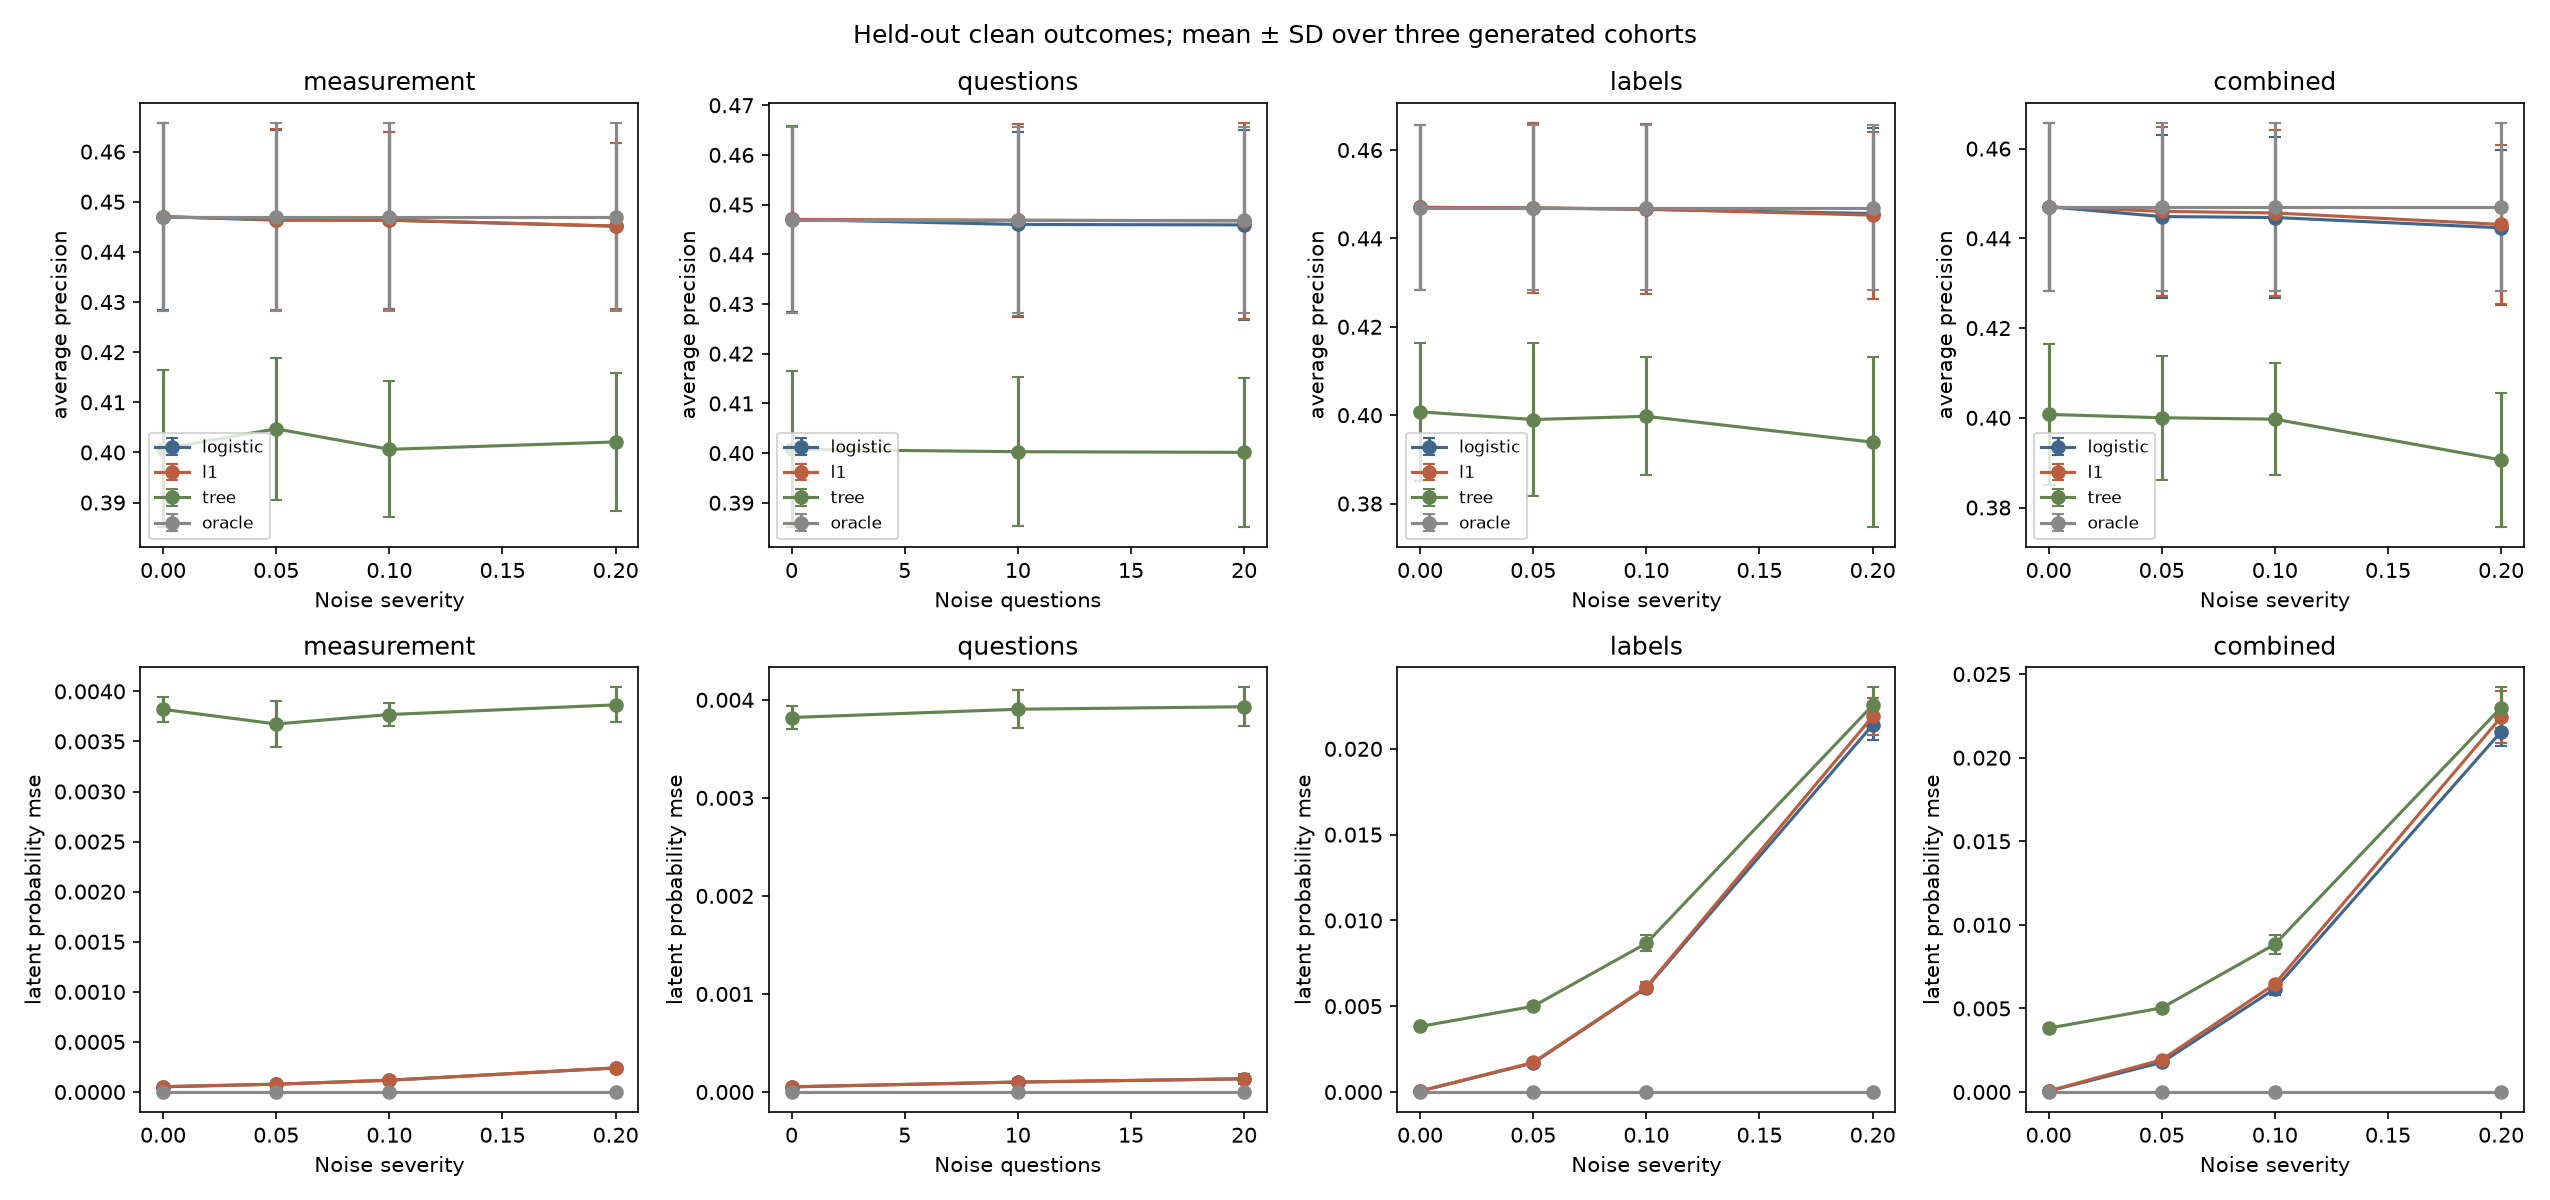

In [6]:
summary = pd.read_csv(OUT / "summary.csv")
display(summary.round(5))
display(Image(filename=str(OUT / "robustness.png")))

## 6. Recovering coefficients and rejecting noise

Coefficient errors are measured in raw feature units against the known generating weights. Under corrupted measurements or labels, the fitted conditional relationship differs from the clean equation; recovery error quantifies departure from that reference rather than ordinary clean-model estimation error.

Nonzero support uses `abs(coefficient)>1e-6`. Sex is a null predictor even though it is not named `Noise_Q`; the outputs distinguish all null variables from added questions. Unpenalized logistic regression almost always gives nonzero sample coefficients to irrelevant variables. Predictive AP selection of L1 regularization does not guarantee exact support recovery.

,seed,scenario,noise_family,level,model,signal_coefficient_rmse,intercept_estimate,raw_intercept_truth,intercept_error,selected_signal_count,selected_null_count,null_count,noise_question_count,selected_noise_questions,selected_feature_count
0,42,clean,clean,0.0,logistic,0.03265,-7.30571,-7.4,0.09429,10,1,1,0,0,11
1,42,clean,clean,0.0,l1,0.03011,-7.26796,-7.4,0.13204,10,1,1,0,0,11
10,42,questions_20,questions,20.0,logistic,0.03270,-7.33881,-7.4,0.06119,10,21,21,20,20,31
11,42,questions_20,questions,20.0,l1,0.03808,-7.01988,-7.4,0.38012,10,2,21,20,2,12
22,42,combined_0.20,combined,0.2,logistic,0.23578,-2.65873,-7.4,4.74127,10,11,11,10,10,21
23,42,combined_0.20,combined,0.2,l1,0.23577,-2.65641,-7.4,4.74359,10,11,11,10,10,21
24,43,clean,clean,0.0,logistic,0.02535,-7.57932,-7.4,-0.17932,10,1,1,0,0,11
25,43,clean,clean,0.0,l1,0.02736,-7.54059,-7.4,-0.14059,10,1,1,0,0,11
34,43,questions_20,questions,20.0,logistic,0.02548,-7.54536,-7.4,-0.14536,10,21,21,20,20,31
35,43,questions_20,questions,20.0,l1,0.05914,-7.26226,-7.4,0.13774,10,3,21,20,2,13


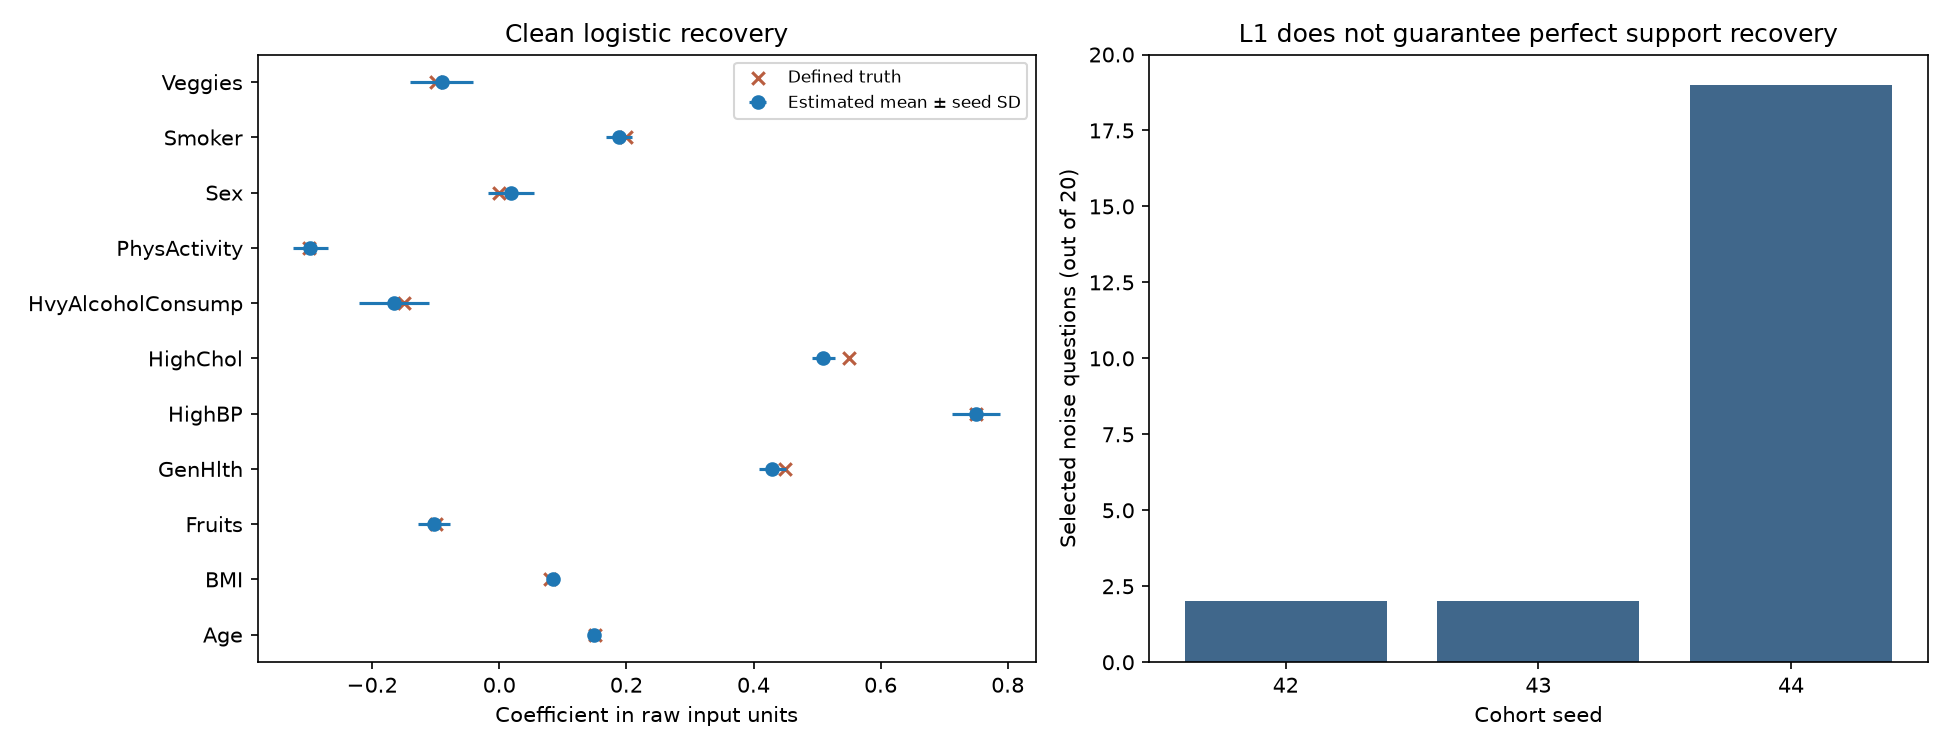

In [7]:
recovery = pd.read_csv(OUT / "recovery.csv")
display(recovery[recovery.scenario.isin(["clean", "questions_20", "combined_0.20"])].round(5))
display(Image(filename=str(OUT / "recovery.png")))

## 7. What the trees learn

Impurity importance is exported for every selected tree. It identifies variables used by that fitted tree, not signed logistic weights. Correlated predictors can share or substitute importance; these importances should not be interpreted as unbiased causal contributions.

In [8]:
tree = pd.read_csv(OUT / "tree_importances.csv")
display(tree[tree.scenario == "clean"].groupby("feature").importance.mean().sort_values(ascending=False).to_frame("mean clean-tree importance"))

,mean clean-tree importance
feature,
GenHlth,0.616593
BMI,0.114157
HighChol,0.103592
Age,0.080303
HighBP,0.079889
PhysActivity,0.002781
Smoker,0.002029
Veggies,0.000655
Fruits,0.000000


## 8. Findings and limits

The clean unpenalized logistic model recovers the assumed equation reasonably well. Its finite-test AP can slightly exceed the oracle's realized AP because the outcomes are random; the oracle remains the true probability reference.

Extra questions have little effect on predictive AP at this sample size, but L1 support varies substantially across cohorts. Symmetric label noise has a clearer effect on probability accuracy than on ranking. For flip rate `r`, the observed conditional probability is `r + (1−2r)p`, which compresses probabilities toward 0.5 while preserving their theoretical ranking when `r<0.5`.

The simulator favors logistic regression because the true equation is logistic. It does not establish that logistic regression is best on real surveys. Most lifestyle variables are sampled independently, reporting errors are stylized, the sample is large relative to its dimensionality, and the cohort prevalence differs from CDC. Future work could examine nonlinear truth, smaller samples, correlated irrelevant variables and asymmetric label errors.

In [9]:
clean_lr = summary[(summary.scenario == "clean") & (summary.model == "logistic")].iloc[0]
noisy_lr = summary[(summary.scenario == "combined_0.20") & (summary.model == "logistic")].iloc[0]
noise_support = recovery[(recovery.scenario == "questions_20") & (recovery.model == "l1")].selected_noise_questions.tolist()
display(Markdown(f"**Clean logistic AP:** {clean_lr.average_precision_mean:.4f} ± {clean_lr.average_precision_std:.4f}. "
    f"**Combined 20% scenario:** AP {noisy_lr.average_precision_mean:.4f}; Brier {noisy_lr.brier_mean:.4f}, "
    f"versus {clean_lr.brier_mean:.4f} when clean. L1 retained {noise_support} of the 20 irrelevant questions across the three seeds."))

**Clean logistic AP:** 0.4470 ± 0.0187. **Combined 20% scenario:** AP 0.4423; Brier 0.1495, versus 0.1281 when clean. L1 retained [2, 2, 19] of the 20 irrelevant questions across the three seeds.